In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
df=pd.read_csv('train.csv')

In [2]:
#1 fill missing age with median
df['Age']=df['Age'].fillna(df['Age'].median())

# 2 fill missing embarked values with the most common part
most_common_embarked=df['Embarked'].mode()[0]
df['Embarked']=df['Embarked'].fillna(most_common_embarked)

#3 convert Sex to numeric: female-> 1,male->0
df['IsFemale']=df['Sex'].map({'female': 1,'male':0})

# select features we want to use for classification
features=['Age','Fare','SibSp','Parch','IsFemale']

print("Preprocessing complete! Here are the features we will use: ")
df[features].head()

Preprocessing complete! Here are the features we will use: 


,Age,Fare,SibSp,Parch,IsFemale
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [3]:
# 2 types of classification
# binary and multi-class
# survived-binary       Pclass-multiclass


x=df[features]
y=df['Survived']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)
print(f"Training set size: {x_train.shape[0]} rows")
print(f"Testing set size: {x_test.shape[0]} rows")

Training set size: 712 rows
Testing set size: 179 rows


In [4]:
binary_model=LogisticRegression(max_iter=1000)
binary_model.fit(x_train,y_train)
y_pred=binary_model.predict(x_test)

accuracy_bin=accuracy_score(y_test,y_pred)
print(f"Binary Classification Acurracy: {accuracy_bin:.4f} ({accuracy_bin*100:.2f}%)")
print("-" * 50)
print("Binary Logistic Regression model trained successfully!")
print(y_pred)

Binary Classification Acurracy: 0.7821 (78.21%)
--------------------------------------------------
Binary Logistic Regression model trained successfully!
[0 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 0
 1 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 0 1
 0 0 1 1 1 1 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1
 0 1 0 1 0 0 0 1 1 0 1 1 0 0 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 1 0 0 1 1 0 0
 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 1 1]


Binary Classification Acurracy: 0.7821 (78.21%)
--------------------------------------------------
[[89 16]
 [23 51]]


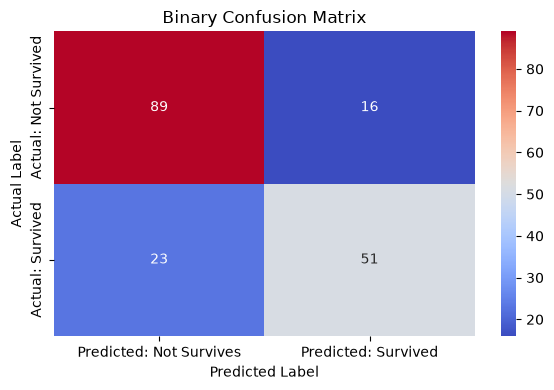

In [5]:
y_pred=binary_model.predict(x_test)

# 1 calculate accuracy
accuracy_bin=accuracy_score(y_test,y_pred)
print(f"Binary Classification Acurracy: {accuracy_bin:.4f} ({accuracy_bin*100:.2f}%)")
print("-" * 50)

# 2 Confusion matrix
cm_bin=confusion_matrix(y_test,y_pred)
print(cm_bin)
plt.figure(figsize=(6,4))
sns.heatmap(cm_bin,annot=True,fmt='d',cmap='coolwarm',xticklabels=['Predicted: Not Survives','Predicted: Survived'],
            yticklabels=['Actual: Not Survived','Actual: Survived'])
plt.title('Binary Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

In [6]:
#15-7-26
# Day - 16
# Multi-class 
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'IsFemale'],
      dtype='str')

In [7]:
features_multi=['Survived','Age','Fare','SibSp','Parch','IsFemale']
x=df[features_multi]
y=df['Pclass']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)
print(f"Training Set : {x_train.shape[0]} rows")
print(f"Testing set size : {x_test.shape[0]} rows")

Training Set : 712 rows
Testing set size : 179 rows


In [8]:
multiclass_model=LogisticRegression(max_iter=1000)
multiclass_model.fit(x_train,y_train)
print("Multiclass Logistic Regression model trained successfully!")

Multiclass Logistic Regression model trained successfully!


Multiclass Classification Accuracy: 0.1397 (13.97 %)


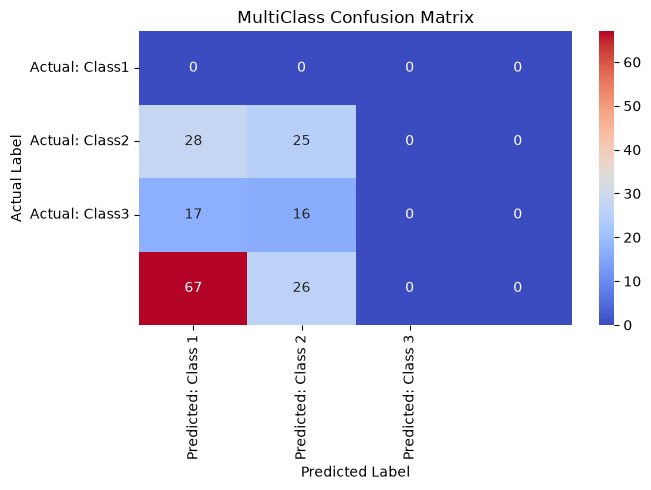

classification Report


ValueError: Number of classes, 4, does not match size of target_names, 3. Try specifying the labels parameter

In [12]:
y_multiclass_pred=multiclass_model.predict(x_train)
accuracy_multi=accuracy_score(y_test,y_pred)
print(f"Multiclass Classification Accuracy: {accuracy_multi:.4f} ({accuracy_multi*100:.2f} %)")
cm_multi=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(cm_multi,annot=True,fmt='d',cmap='coolwarm',xticklabels=['Predicted: Class 1','Predicted: Class 2','Predicted: Class 3'],
            yticklabels=['Actual: Class1','Actual: Class2','Actual: Class3'])
plt.title('MultiClass Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Classification Report
print("classification Report")
print(classification_report(y_test,y_pred,target_names=['Class 1','Class 2','Class 3']))